In [1]:
!cd ../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/5d/40/e1e72872c6354b306daef1703549e8e83b4d43cfea356311bf722a043752/setuptools-83.0.0-py3-none-any.whl.metadata
    Using cached setuptools-83.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-83.0.0-py3-none-any.whl (1.0 MB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 83.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

# Overview of input GBIF cases

In [2]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import itertools as ittls

In [3]:
gbif_cases = pd.read_csv("../runtime/full_gbif_cases.csv")

In [4]:
gbif_cases.describe()

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,data_standard,year,best_oa_location.repository_institution,first_oa_location.repository_institution,best_oa_location,first_oa_location
count,179.000000,179.000000,179.000000,179.000000,179.000000,179.0,179.000000,0.0,0.0,0.0,0.0
mean,89.000000,105.424581,142.273743,153.513966,153.513966,2.0,2024.000000,NaN,NaN,NaN,NaN
std,51.816986,63.071376,92.272483,99.156009,99.156009,0.0,1.323937,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,2.0,2022.000000,NaN,NaN,NaN,NaN
25%,44.500000,53.500000,62.000000,68.000000,68.000000,2.0,2023.000000,NaN,NaN,NaN,NaN
50%,89.000000,100.000000,139.000000,151.000000,151.000000,2.0,2024.000000,NaN,NaN,NaN,NaN
75%,133.500000,161.500000,217.500000,233.500000,233.500000,2.0,2025.000000,NaN,NaN,NaN,NaN
max,178.000000,212.000000,314.000000,336.000000,336.000000,2.0,2026.000000,NaN,NaN,NaN,NaN


In [5]:
for c in gbif_cases.columns:
    print(c)

Unnamed: 0.4
Unnamed: 0.3
Unnamed: 0.2
Unnamed: 0.1
Unnamed: 0
title
authors
source
published
open_access
peer_review
citation_type
countries_of_coverage
countries_of_researcher
keywords
literature_type
websites
identifiers
id
abstract
topics
added
gbif_download_key
literature_metadata
gbif_data_id_data
dataset_metadata
dwca_url
data_standard
doi_url
genre
has_repository_copy
is_oa
is_paratext
journal_is_in_doaj
journal_is_oa
journal_issn_l
journal_issns
journal_name
oa_locations
oa_locations_embargoed
oa_status
published_date
publisher
title_unp
updated
year
z_authors
best_oa_location.endpoint_id
best_oa_location.evidence
best_oa_location.host_type
best_oa_location.is_best
best_oa_location.license
best_oa_location.oa_date
best_oa_location.pmh_id
best_oa_location.repository_institution
best_oa_location.updated
best_oa_location.url
best_oa_location.url_for_landing_page
best_oa_location.url_for_pdf
best_oa_location.version
first_oa_location.endpoint_id
first_oa_location.evidence
first_oa

## Statistic constructs

In [6]:
from typing import TypedDict

class MetricSummary(TypedDict):
    mean: float
    median: float
    min: float
    max: float
    std: float

def get_summary(series: pd.Series) -> MetricSummary:
    """Computes standard descriptive statistics for a numeric series."""
    return {
        "mean": float(series.mean()),
        "median": float(series.median()),
        "min": float(series.min()),
        "max": float(series.max()),
        "std": float(series.std())
    }

## Preprocessing

In [7]:
import ast

In [8]:
gbif_cases["paper_download_info_dict"] = gbif_cases["paper_download_info"].apply(ast.literal_eval)

In [9]:
gbif_cases["dwca_zip_info_dict"] = gbif_cases["dwca_zip_info"].apply(ast.literal_eval)

## EDA

In [10]:
import pprint

### Basic Stats

In [11]:
class DwCArchiveStats(TypedDict):
    dwca_compressed_bytes: MetricSummary
    dwca_raw_bytes: MetricSummary
    dwca_file_count: MetricSummary
    dwca_compression_ratio: MetricSummary

class DataPaperStats(TypedDict):
    pdf_page_count: MetricSummary
    pdf_size_bytes: MetricSummary

In [12]:
def reduce_to_dwca_stats(df_dwca: pd.DataFrame) -> DwCArchiveStats:
    return {
        "dwca_compressed_bytes": get_summary(df_dwca['compressed_size_bytes']),
        "dwca_raw_bytes": get_summary(df_dwca['raw_size_bytes']),
        "dwca_file_count": get_summary(df_dwca['total_file_count']),
        "dwca_compression_ratio": get_summary(df_dwca['compression_ratio']),
    }

In [13]:
dwca_infos = gbif_cases["dwca_zip_info_dict"].apply(pd.Series)
dwca_stats = reduce_to_dwca_stats(dwca_infos)

In [14]:
pprint.pprint(dwca_stats)

{'dwca_compressed_bytes': {'max': 488503550.0,
                           'mean': 4439663.899441341,
                           'median': 102038.0,
                           'min': 2506.0,
                           'std': 38026006.08860089},
 'dwca_compression_ratio': {'max': 69.71,
                            'mean': 16.880893854748603,
                            'median': 14.29,
                            'min': 3.3,
                            'std': 10.618255283423487},
 'dwca_file_count': {'max': 6.0,
                     'mean': 3.5810055865921786,
                     'median': 3.0,
                     'min': 3.0,
                     'std': 0.7250548952267064},
 'dwca_raw_bytes': {'max': 5725386981.0,
                    'mean': 62521519.5698324,
                    'median': 1748313.0,
                    'min': 8682.0,
                    'std': 451357039.05675966}}


In [15]:
def reduce_to_datapaper_stats(df_pdf: pd.DataFrame) -> DataPaperStats:
    return {
        "pdf_page_count": get_summary(df_pdf['nr_pages']),
        "pdf_size_bytes": get_summary(df_pdf['file_size_bytes'] ),
    }

In [16]:
paper_infos = gbif_cases["paper_download_info_dict"].apply(pd.Series)
datapaper_stats = reduce_to_datapaper_stats(paper_infos)

In [17]:
pprint.pprint(datapaper_stats)

{'pdf_page_count': {'max': 46.0,
                    'mean': 14.134078212290502,
                    'median': 13.0,
                    'min': 1.0,
                    'std': 8.81354362627629},
 'pdf_size_bytes': {'max': 6490174.0,
                    'mean': 1097364.6033519553,
                    'median': 609919.0,
                    'min': 409.0,
                    'std': 1218961.5932249508}}


In [18]:
gbif_cases.groupby(["year", "source"]).count().unstack()

Unnamed: 0.4                                   \
source Annals of Forest Science Arxius de Miscel·lània Zoològica   
year                                                               
2022                        NaN                              1.0   
2023                        NaN                              2.0   
2024                        1.0                              2.0   
2025                        NaN                              2.0   
2026                        NaN                              1.0   

                                                                           \
source Biodiversity Data Journal Biota Colombiana Data Diversity Gigabyte   
year                                                                        
2022                        10.0              NaN  2.0       2.0      9.0   
2023                        14.0              3.0  4.0       5.0      3.0   
2024                        24.0              NaN  1.0       NaN      3.0   
2025                        26.0              NaN  NaN       1.0      NaN   
2026                        15.0              NaN  NaN       NaN      9.0   

                                                                \
source Journal of Limnology Management of Biological Invasions   
year                                                             
2022                    NaN                                NaN   
2023                   10.0                                NaN   
2024                    NaN                                1.0   
2025                    1.0                                NaN   
2026                    NaN                                NaN   

                                          ... dwca_zip_info_dict  \
source Medical and Veterinary Entomology  ...           Gigabyte   
year                                      ...                      
2022                                 NaN  ...                9.0   
2023                                 NaN  ...                3.0   
2024                                 NaN  ...                3.0   
2025                                 NaN  ...                NaN   
2026                                 1.0  ...                9.0   

                                                                \
source Journal of Limnology Management of Biological Invasions   
year                                                             
2022                    NaN                                NaN   
2023                   10.0                                NaN   
2024                    NaN                                1.0   
2025                    1.0                                NaN   
2026                    NaN                                NaN   

                                                                             \
source Medical and Veterinary Entomology MycoKeys PhytoKeys Scientific Data   
year                                                                          
2022                                 NaN      NaN       1.0             2.0   
2023                                 NaN      NaN       NaN             2.0   
2024                                 NaN      1.0       NaN             6.0   
2025                                 NaN      NaN       NaN             5.0   
2026                                 1.0      NaN       NaN             1.0   

                                     
source Specimen ZooKeys Zoosymposia  
year                                 
2022        NaN     NaN         NaN  
2023        NaN     NaN         1.0  
2024        2.0     NaN         NaN  
2025        NaN     1.0         NaN  
2026        4.0     NaN         NaN  

[5 rows x 1344 columns]

### Metadata Stats

In [19]:
class MetadataFileStats(TypedDict):
    schema: str
    
    grand_nr_elements: MetricSummary
    grand_nr_unique_elements: MetricSummary
    group_nr_elements: MetricSummary
    group_nr_unique_elements: MetricSummary
    total_nr_unique_elements: int
    
    grand_nr_attributes: MetricSummary
    grand_nr_unique_attributes: MetricSummary
    group_nr_attributes: MetricSummary
    group_nr_unique_attributes: MetricSummary
    total_nr_unique_attributes: int

    grand_nr_text_nodes: MetricSummary
    group_nr_text_nodes: MetricSummary

    grand_element_depth: MetricSummary
    group_element_depth: MetricSummary

    
    grand_element_fanout_degree: MetricSummary
    group_element_fanout_degree: MetricSummary
    
    grand_element_to_attribute_degree: MetricSummary
    group_element_to_attribute_degree: MetricSummary

    grand_text_content_length: MetricSummary
    group_text_content_length: MetricSummary

In [20]:
from dataclasses import dataclass
from typing import List, Optional, Set

@dataclass
class Element:
    tag: str
    depth: int
    nr_attributes: int
    nr_unique_attributes: int
    fanout: int  # Number of direct children
    text_length: int
    attribute_names: Set[str]

class MetadataOverview(TypedDict):
    elements: List[Element]

In [21]:
def is_hidden_file(fn: str) -> bool:
    return any((
        fn.startswith("__"),  # reserved/hidden files, e.g. __MACOSX
        fn.startswith("."),   # hidden files UNIX
    ))

def is_metadata_xml(fn: str) -> bool:
    """Check for xml but be aware of zip artifacts"""
    return fn.endswith(".xml") and not is_hidden_file(fn)

In [22]:
eml_files = gbif_cases["ground_truth_metadata_eml"]
dwc_files = gbif_cases["ground_truth_metadata_dwc"]

In [23]:
eml_files

0      ground_truth/data/000-6f97bcef-7324-3425-bb72-...
1      ground_truth/data/001-2fee34a0-a302-3c12-8916-...
2      ground_truth/data/002-325b19cf-6c16-3147-b8db-...
3      ground_truth/data/003-d72b6b4f-0fb1-301e-81d0-...
4      ground_truth/data/004-93ed8a30-2f05-37c7-a371-...
                             ...                        
174    ground_truth/data/208-8395f577-f4ec-3cc9-9d46-...
175    ground_truth/data/209-1cf45154-9800-31c6-ba38-...
176    ground_truth/data/210-99ee49cb-8bcd-39a4-895b-...
177    ground_truth/data/211-5ef32ca0-b247-30f8-aed8-...
178    ground_truth/data/212-74a27d9e-8cac-36c2-a743-...
Name: ground_truth_metadata_eml, Length: 179, dtype: str

In [24]:
from pathlib import Path

EXPERIMENT_BASE_DIR = "../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [25]:
from lxml import etree

def parse_files_to_df(file_series: pd.Series) -> pd.DataFrame:
    """
    Parses a series of file paths into a single flattened DataFrame.
    Each row is an element; 'file_path' acts as the grouping key.
    """
    all_rows = []

    for path in file_series:
        if not path: continue
        try:
            tree = etree.parse(path)
            for node in tree.iter():
                # Extract properties for our 'Element' representation
                attrs = node.attrib
                text = node.text.strip() if node.text else ""

                all_rows.append({
                    "file_path": path,
                    "tag": node.tag,
                    "depth": sum(1 for _ in node.iterancestors()),
                    "nr_attributes": len(attrs),
                    "nr_unique_attributes": len(set(attrs.keys())),
                    "fanout": len(node),
                    "text_length": len(text),
                    "attr_names": set(attrs.keys()),
                    "is_text_node": bool(text) ,
                    "text_content": text,
                })
        except Exception as e:
            print(f"Skipping {path} due to error: {e}")

    return pd.DataFrame(all_rows)

In [26]:
def create_metadata_dataframes(file_series: pd.Series):
    # 1. Element-level (the one we built previously)
    el_df = parse_files_to_df(file_series)
    
    # 2. File-level (Aggregating elements by file_path)
    file_df = el_df.groupby("file_path").agg(
        nr_elements=('tag', 'count'),
        nr_unique_elements=('tag', 'nunique'),
        total_attributes=('nr_attributes', 'sum'),
        avg_depth=('depth', 'mean'),
        max_depth=('depth', 'max'),
        avg_fanout=('fanout', 'mean'),
        total_text_length=('text_length', 'sum'),
        nr_text_nodes=('text_length', lambda x: (x > 0).sum())
    ).reset_index()
    
    # Add calculated density columns for plotting
    file_df['attr_density'] = file_df['total_attributes'] / file_df['nr_elements']
    
    return el_df, file_df

In [27]:
def get_metadata_file_stats(el_df: pd.DataFrame, file_df: pd.DataFrame, schema: str) -> MetadataFileStats:
    # Grand (Pooled) - using Element DF
    total_unique_elements = el_df['tag'].nunique()
    total_unique_attrs = len(set().union(*el_df['attr_names']))
    
    # Group (Distribution of file properties) - using File DF
    return {
        "schema": schema,
        
        # Elements
        "grand_nr_elements": get_summary(file_df['nr_elements']), 
        "grand_nr_unique_elements": get_summary(file_df['nr_unique_elements']),
        "group_nr_elements": get_summary(file_df['nr_elements']), 
        "group_nr_unique_elements": get_summary(file_df['nr_unique_elements']),
        "total_nr_unique_elements": total_unique_elements,
        
        # Attributes
        "grand_nr_attributes": get_summary(file_df['total_attributes']),
        "grand_nr_unique_attributes": get_summary(el_df.groupby("file_path")['nr_unique_attributes'].mean()), 
        "group_nr_attributes": get_summary(el_df.groupby("file_path")['nr_attributes'].mean()),
        "total_nr_unique_attributes": total_unique_attrs,

        # Structure & Content
        "grand_element_depth": get_summary(el_df['depth']),  # Pooled
        "group_element_depth": get_summary(file_df['avg_depth']), # Mean of means
        
        "grand_element_fanout_degree": get_summary(el_df['fanout']),
        "group_element_fanout_degree": get_summary(file_df['avg_fanout']),

        "grand_text_content_length": get_summary(el_df[el_df['text_length'] > 0]['text_length']),
        "group_text_content_length": get_summary(file_df['total_text_length']),
        
        "grand_nr_text_nodes": get_summary(file_df['nr_text_nodes']),
        "group_nr_text_nodes": get_summary(file_df['nr_text_nodes']), # Summarizing the counts
        
        "grand_element_to_attribute_degree": get_summary(el_df['nr_attributes']),
        "group_element_to_attribute_degree": get_summary(file_df['attr_density']),
    }

In [28]:
eml_element_overviews, eml_file_overviews = create_metadata_dataframes(eml_files.apply(grounded_path))

In [29]:
dwc_element_overviews, dwc_file_overviews = create_metadata_dataframes(dwc_files.apply(grounded_path))

In [30]:
dwc_element_overviews[dwc_element_overviews["is_text_node"]]["tag"].unique()

array(['{http://rs.tdwg.org/dwc/text/}location',
       <cyfunction Comment at 0x116150870>], dtype=object)

In [31]:
dwc_element_overviews["tag"].unique().shape[0]

9

## Report

In [53]:
paper_infos["nr_pages"].describe()

count    179.000000
mean      14.134078
std        8.813544
min        1.000000
25%        9.000000
50%       13.000000
75%       18.000000
max       46.000000
Name: nr_pages, dtype: float64

In [59]:
pprint.pprint(paper_infos.groupby('nr_pages').count()["file_size_bytes"])
pprint.pprint((paper_infos.groupby('nr_pages').count()["file_size_bytes"] / 179) * 100)

nr_pages
1     15
2      4
4      1
5      3
6      4
7     10
8      7
9      8
10    11
11    14
12    11
13     9
14    12
15     7
16     6
17     6
18     7
19     3
20     7
21     2
22     3
23     4
24     4
25     2
26     3
27     3
29     2
30     1
31     2
33     2
34     2
37     1
42     1
45     1
46     1
Name: file_size_bytes, dtype: int64
nr_pages
1     8.379888
2     2.234637
4     0.558659
5     1.675978
6     2.234637
7     5.586592
8     3.910615
9     4.469274
10    6.145251
11    7.821229
12    6.145251
13    5.027933
14    6.703911
15    3.910615
16    3.351955
17    3.351955
18    3.910615
19    1.675978
20    3.910615
21    1.117318
22    1.675978
23    2.234637
24    2.234637
25    1.117318
26    1.675978
27    1.675978
29    1.117318
30    0.558659
31    1.117318
33    1.117318
34    1.117318
37    0.558659
42    0.558659
45    0.558659
46    0.558659
Name: file_size_bytes, dtype: float64


In [40]:
dwca_infos["data_file_count"] = (dwca_infos['total_file_count'] - 2)

In [51]:
# percentages of the file counts
pprint.pprint(dwca_infos.groupby('data_file_count').count()["total_file_count"])
pprint.pprint((dwca_infos.groupby('data_file_count').count()["total_file_count"] / 179) * 100)

data_file_count
1    97
2    63
3    16
4     3
Name: total_file_count, dtype: int64
data_file_count
1    54.189944
2    35.195531
3     8.938547
4     1.675978
Name: total_file_count, dtype: float64


In [72]:
dwc_file_overviews["size"] = dwc_file_overviews["nr_elements"]
dwc_file_overviews["size_attr"] = dwc_file_overviews["nr_elements"] + dwc_file_overviews["total_attributes"]

eml_file_overviews["size"] = eml_file_overviews["nr_elements"]
eml_file_overviews["size_attr"] = eml_file_overviews["nr_elements"] + eml_file_overviews["total_attributes"]

In [35]:
dwc_file_overviews[["size", "size_attr"]].describe()

,size,size_attr
count,179.000000,179.000000
mean,49.307263,145.648045
std,23.171091,69.174134
min,12.000000,34.000000
25%,33.500000,98.500000
50%,45.000000,134.000000
75%,61.000000,180.000000
max,202.000000,603.000000


<Axes: ylabel='Frequency'>

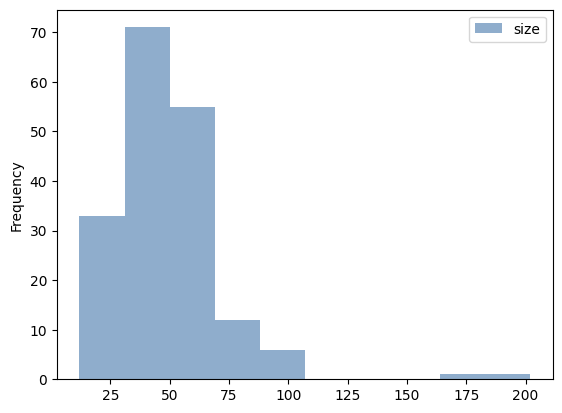

In [82]:
dwc_file_overviews[["size"]].plot.hist(alpha=0.6)

<Axes: ylabel='Frequency'>

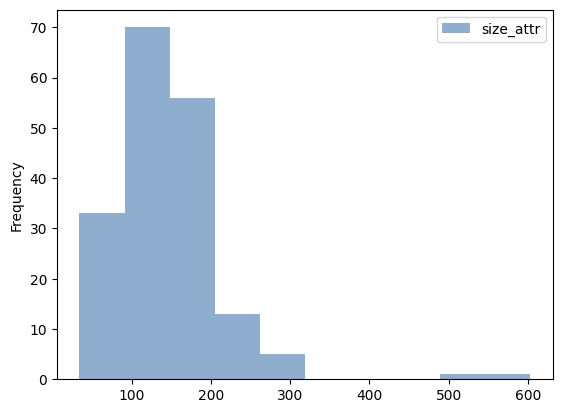

In [83]:
dwc_file_overviews[["size_attr"]].plot.hist(alpha=0.6)

In [86]:
(dwc_file_overviews["size_attr"] / dwc_file_overviews["size"]).describe()

count    179.000000
mean       2.948139
std        0.033823
min        2.833333
25%        2.931426
50%        2.948718
75%        2.956202
max        3.090909
dtype: float64

In [73]:
eml_file_overviews[["size", "size_attr"]].describe()

,size,size_attr
count,179.000000,179.000000
mean,299.810056,318.055866
std,494.601131,497.944739
min,31.000000,36.000000
25%,142.000000,153.500000
50%,206.000000,224.000000
75%,331.500000,357.500000
max,6326.000000,6347.000000


In [88]:
(eml_file_overviews["size_attr"] / eml_file_overviews["size"]).describe()

count    179.000000
mean       1.077726
std        0.034424
min        1.003320
25%        1.054033
50%        1.075581
75%        1.095698
max        1.265873
dtype: float64

In [74]:
dwc_element_overviews["out"] = dwc_element_overviews["fanout"]

eml_element_overviews["out"] = eml_element_overviews["fanout"]

In [65]:
dwc_element_overviews[["depth", "out"]].describe()

,depth,out
count,8826.000000,8826.000000
mean,1.959438,0.979719
std,0.377779,6.172877
min,0.000000,0.000000
25%,2.000000,0.000000
50%,2.000000,0.000000
75%,2.000000,0.000000
max,3.000000,185.000000


In [89]:
dwc_element_overviews[dwc_element_overviews["out"] > 0][["depth", "out"]].describe()

,depth,out
count,737.000000,737.000000
mean,1.135685,11.732700
std,0.777076,18.181241
min,0.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,2.000000,21.000000
max,2.000000,185.000000


In [75]:
eml_element_overviews[["depth", "out"]].describe()

,depth,out
count,53666.000000,53666.000000
mean,3.823166,0.996665
std,1.006971,9.408301
min,0.000000,0.000000
25%,3.000000,0.000000
50%,4.000000,0.000000
75%,5.000000,2.000000
max,8.000000,2052.000000


In [98]:
eml_element_overviews[(eml_element_overviews["out"] > 0) & (eml_element_overviews["out"] < 2000)][["depth", "out"]].describe()

,depth,out
count,17741.000000,17741.000000
mean,3.201342,2.899217
std,0.930530,5.001137
min,0.000000,1.000000
25%,3.000000,2.000000
50%,3.000000,2.000000
75%,4.000000,3.000000
max,7.000000,292.000000


<Axes: ylabel='Frequency'>

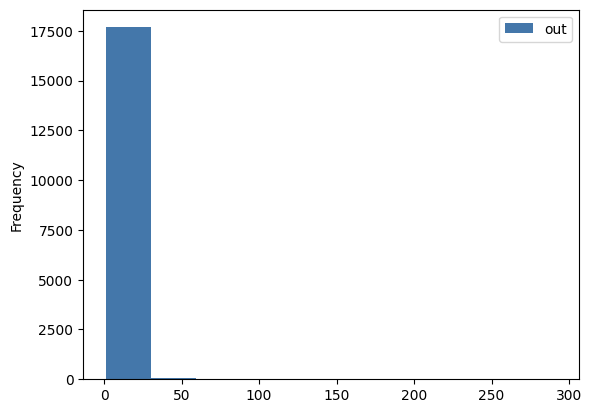

In [101]:
eml_element_overviews[(eml_element_overviews["out"] > 0) & (eml_element_overviews["out"] < 2000)][["out"]].plot.hist()

In [70]:
# percentages of the depths counts
pprint.pprint(dwc_element_overviews.groupby('depth').count()["out"])
pprint.pprint((dwc_element_overviews.groupby('depth').count()["out"] / dwc_element_overviews.shape[0]) * 100)

depth
0     179
1     279
2    8089
3     279
Name: out, dtype: int64
depth
0     2.028099
1     3.161115
2    91.649671
3     3.161115
Name: out, dtype: float64


In [78]:
# percentages of the depths counts
pprint.pprint(eml_element_overviews.groupby('depth').count()["out"])
pprint.pprint((eml_element_overviews.groupby('depth').count()["out"] / eml_element_overviews.shape[0]) * 100)

depth
0      179
1      359
2     4507
3    14677
4    18544
5    14858
6      494
7       44
8        4
Name: out, dtype: int64
depth
0     0.333545
1     0.668952
2     8.398241
3    27.348787
4    34.554467
5    27.686058
6     0.920508
7     0.081989
8     0.007454
Name: out, dtype: float64


In [77]:
# percentages of the outs counts
pprint.pprint(dwc_element_overviews.groupby('out').count()["depth"])
pprint.pprint((dwc_element_overviews.groupby('out').count()["depth"] / dwc_element_overviews.shape[0]) * 100)

out
0      8089
1       377
2        64
3        16
4         4
       ... 
76        2
81        1
83        1
167       1
185       1
Name: depth, Length: 67, dtype: int64
out
0      91.649671
1       4.271471
2       0.725130
3       0.181283
4       0.045321
         ...    
76      0.022660
81      0.011330
83      0.011330
167     0.011330
185     0.011330
Name: depth, Length: 67, dtype: float64


In [87]:
# percentages of the outs counts
pprint.pprint(eml_element_overviews.groupby('out').count()["depth"])
pprint.pprint((eml_element_overviews.groupby('out').count()["depth"] / eml_element_overviews.shape[0]) * 100)

out
0       35924
1        4108
2        8911
3        1233
4         915
        ...  
117         2
131         1
159         1
292         1
2052        1
Name: depth, Length: 76, dtype: int64
out
0       66.939962
1        7.654753
2       16.604554
3        2.297544
4        1.704990
          ...    
117      0.003727
131      0.001863
159      0.001863
292      0.001863
2052     0.001863
Name: depth, Length: 76, dtype: float64


## Visualise

- Structural overview
- Most frequent attributes

In [32]:
mpl.rc('xtick', labelsize=6)
mpl.rc('ytick', labelsize=6)

In [33]:
# Reusable subplot builder
def column_subplots(fig, subplot_source, data):
    for i, (l, lps, vsx, props, opts) in enumerate(data):
        ax = fig.add_subplot(subplot_source[i])
        ax.tick_params(axis="x", bottom=True, top=False)
        if (xscale := opts.get("xscale", "")):
            ax.set_xscale(xscale)
        if opts.get("boxplots", False):
            ax.boxplot(
                [vs for t, vs in vsx],
                tick_labels=[t for t, vs in vsx],
                flierprops=dict(markersize=2),
                zorder=10,
                **props
            )
            ax.set_xlabel(xl, fontsize=4) if (xl:=opts.get("xlabel", "")) else ...
            ax.set_ylabel(yl, fontsize=4) if (yl:=opts.get("ylabel", "")) else ...
        else:
            for t, vs in vsx:
                ax.hist(vs, **props, label=t, zorder=10)
                ax.set_xlabel(t, fontsize=4) if t else ...
        if (vlines := opts.get("vlines", [])):
            tway = ax.twiny()
            tway.set_xlim(ax.get_xlim())
            if (xscale := opts.get("xscale", "")):
                tway.set_xscale(xscale)
            for vl, vl_props in vlines:
                ax.axvline(
                    vl,
                    zorder=0,
                    **vl_props,
                )
            tway.set_xticks([vl for vl, _ in vlines])
            tway.set_xticklabels([vlp["label"] for _, vlp in vlines], fontsize=4, color="gray", rotation=90, fontstyle="italic")
            tway.tick_params(axis="x", color="gray", pad=1, length=1.75, labelfontfamily="serif")
            tway.minorticks_off()
        if (hists := opts.get("hists", [])):
            twax = ax.twinx()
            twax.set_xlim(ax.get_xlim())
            if (xscale := opts.get("xscale", "")):
                twax.set_xscale(xscale)
            for ht, ht_props in hists:
                twax.hist(
                    ht,
                    zorder=0,
                    **ht_props,
                )
            twax.set_yticks([],[])
        if opts.get("legend", False):
            ax.legend(fontsize=4)
        ax.set_title(l, size=8, **lps)

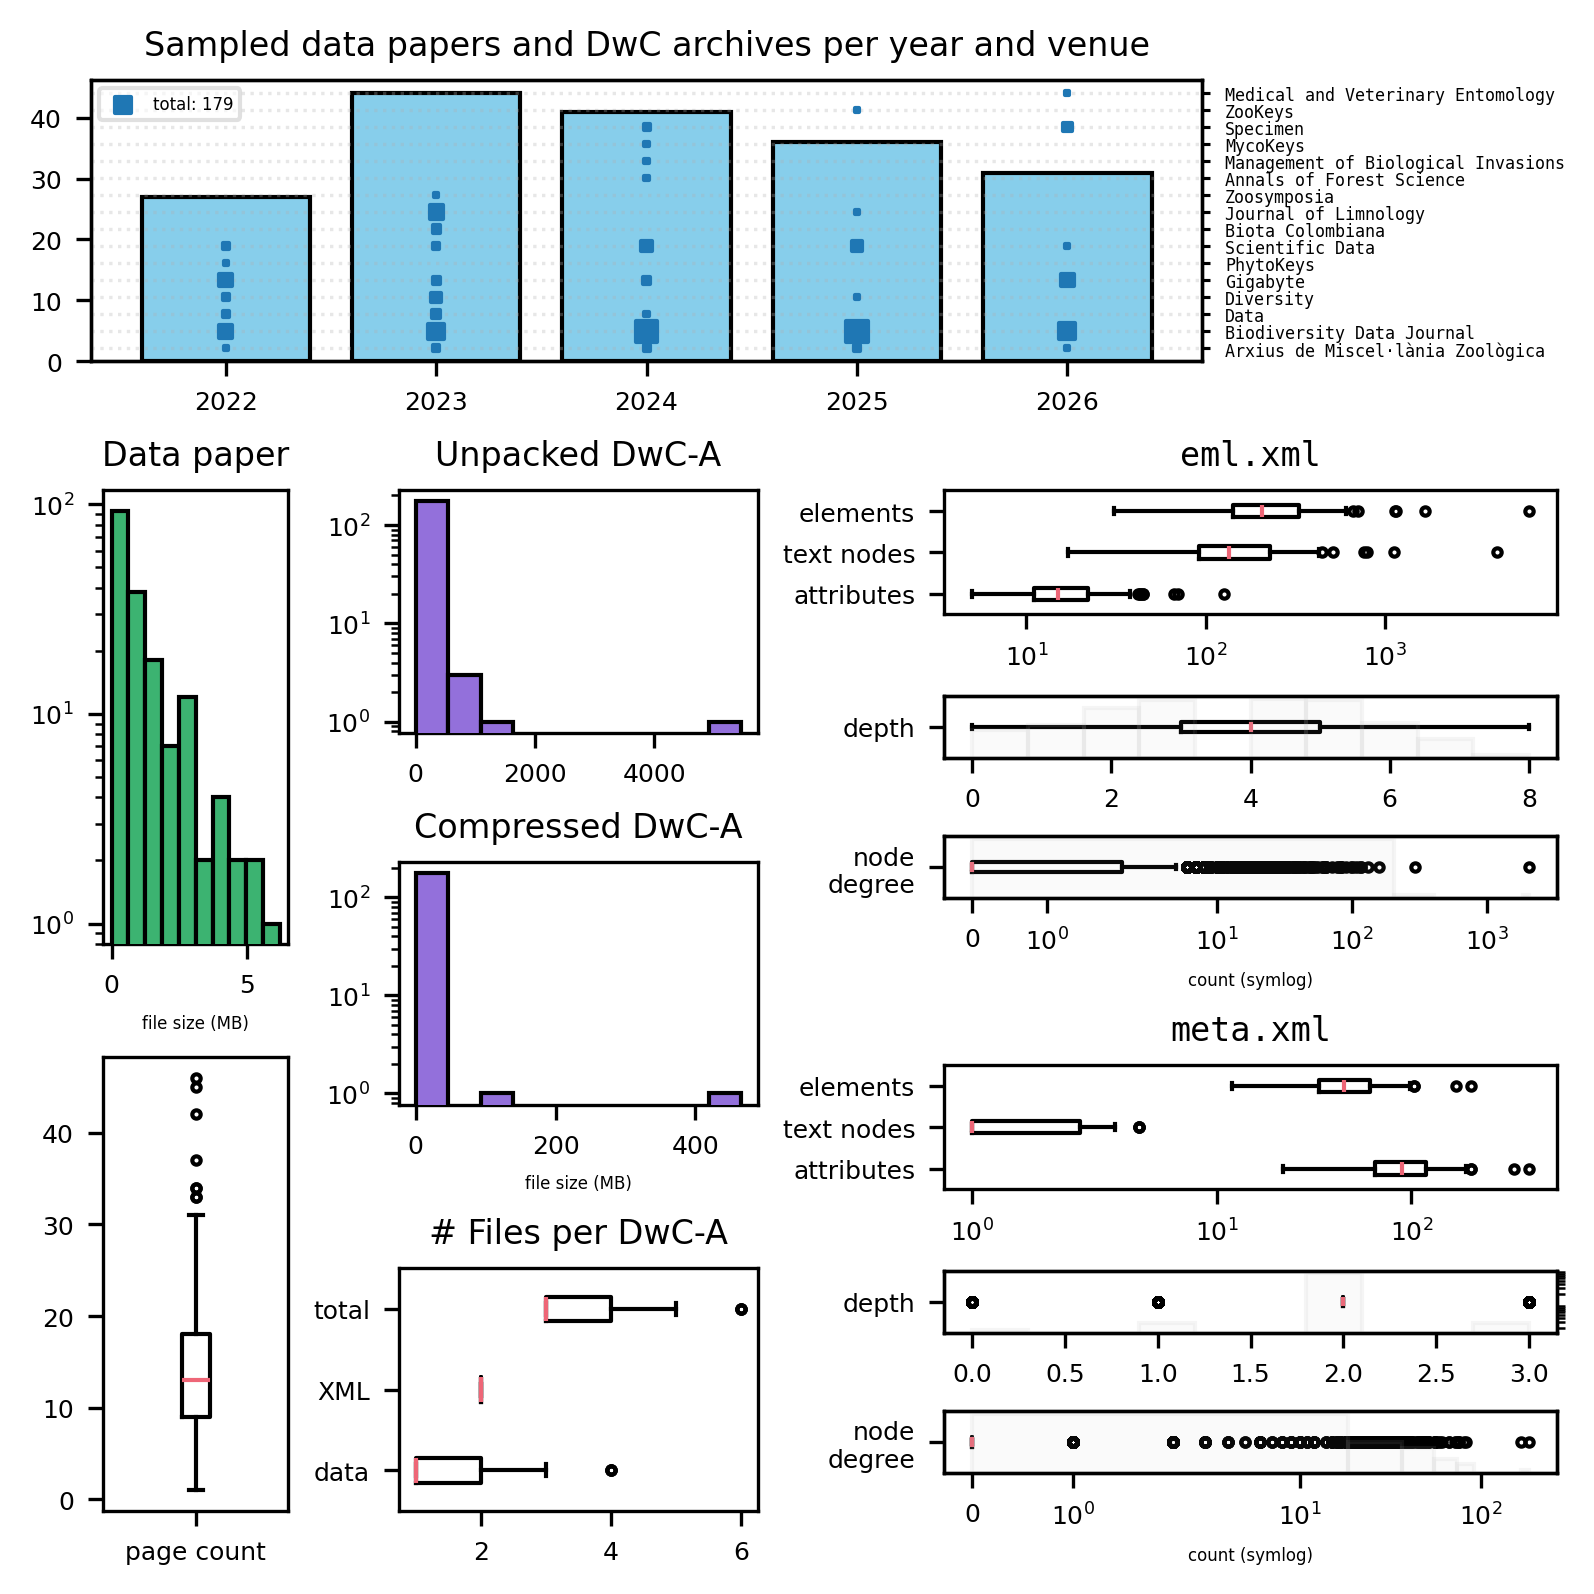

In [34]:
figsize = (5.2, 5.2)
dpi = 300
layout = """
    AAAAA
    BCCDD
    BCCDD
    BCCDD
    BCCDD
"""

fig, axd = plt.subplot_mosaic(
    layout,
    figsize=figsize,
    dpi=dpi,
    constrained_layout=True
)

# Subplot 1: Year x Venue Histogram
axd['A'].set_title('Sampled data papers and DwC archives per year and venue', fontsize=8)
years = gbif_cases.groupby(["year"]).size().reset_index(name='count')
sizes = gbif_cases.groupby(["year", "source"]).size().reset_index(name='count')
axd['A'].bar(years["year"], years["count"], color='skyblue', edgecolor='black')
twinx_a = axd['A'].twinx()
twinx_a.grid(alpha=0.3, ls=":")
twinx_a.set_axisbelow(True)
twinx_a.tick_params(which='major', width=0.75, length=2, labelsize=4, labelfontfamily='monospace')
twinx_a.scatter(
    sizes["year"],
    sizes["source"],
    s=sizes["count"],
    marker="s",
    color="tab:blue",
    label=f"total: {gbif_cases.shape[0]}"
)
twinx_a.legend(fontsize=4, loc=2, framealpha=0.6)

# Subplot 2: Paper Info
# filesize, number of pages
gs_b = axd['B'].get_subplotspec().subgridspec(2, 1)
column_subplots(
    fig,
    gs_b,
    [
        ("Data paper", {}, [("file size (MB)", paper_infos["file_size_bytes"] / (1024 ** 2))], dict(log=True, color="mediumseagreen", edgecolor='black'), {}),
        ("", {}, [("page count", paper_infos["nr_pages"])], dict(vert=True), dict(boxplots=True, xlabel="\n")),
    ],
)
axd['C'].axis('off') # Hide the parent container

# Subplot 3: DwC info
gs_c = axd['C'].get_subplotspec().subgridspec(3, 1)
column_subplots(
    fig,
    gs_c,
    [
        ("Unpacked DwC-A", {}, [("", dwca_infos["raw_size_bytes"] / (1024 ** 2))], dict(log=True, color="mediumpurple", edgecolor='black'), {}),
        ("Compressed DwC-A", {}, [("file size (MB)", dwca_infos["compressed_size_bytes"] / (1024 ** 2))], dict(log=True, color="mediumpurple", edgecolor='black'), {}),
        (
            "# Files per DwC-A", {},
            [
                ("data", dwca_infos["included_file_names"].apply(lambda fs: [f for f in fs if not is_metadata_xml(f)]).apply(len)),
                ("XML", dwca_infos["included_file_names"].apply(lambda fs: [f for f in fs if is_metadata_xml(f)]).apply(len)),
                ("total", dwca_infos["included_file_names"].apply(len)),
            ],
            dict(vert=False),
            dict(boxplots=True)
        ),
    ],
)
axd['B'].axis('off') # Hide the parent container


# Subplot 4: EML & DwC-Text Metadata Info
gs_d = axd['D'].get_subplotspec().subgridspec(6, 1, height_ratios=[2,1,1,2,1,1])
column_subplots(
    fig,
    gs_d,
    [
        (
            "eml.xml", dict(fontfamily="monospace"),
            [
                ("attributes", eml_file_overviews["total_attributes"]),
                ("text nodes", eml_file_overviews["nr_text_nodes"]),
                ("elements", eml_file_overviews["nr_elements"]),
            ],
            dict(vert=False),
            dict(
                boxplots=True, 
                xscale="symlog", 
                # vlines=[
                #     (
                #         eml_element_overviews["tag"].unique().shape[0],
                #         dict(ls="-.", color="#aeaeae4d", linewidth=1, label="|e|")
                #     ),
                #     (
                #         eml_element_overviews[eml_element_overviews["is_text_node"]]["tag"].unique().shape[0], 
                #         dict(ls="--", color="#aeaeae4d", linewidth=1, label="|t|")                        
                #     ),
                #     (
                #         len(set(list(ittls.chain.from_iterable(eml_element_overviews["attr_names"].tolist())))),
                #         dict(ls=":", color="#aeaeae4d", linewidth=1, label="|a|")      
                #     ),
                # ]
            )
        ),
        (
            "", 
            {},
            [("depth", eml_element_overviews["depth"])],
            dict(vert=False),
            dict(boxplots=True, hists=[(eml_element_overviews["depth"], dict(log=True, ls="-", color="#aeaeae0d", edgecolor="#aeaeae1d", linewidth=1))])
        ),
        (
            "", 
            {},
            [("node\ndegree", eml_element_overviews["fanout"])],
            dict(vert=False),
            dict(
                boxplots=True, 
                xlabel="count (symlog)", 
                xscale="symlog", 
                hists=[(eml_element_overviews["fanout"], dict(log=True, ls="-", color="#aeaeae0d", edgecolor="#aeaeae1d", linewidth=1))]
            )
        ),
        (
            "meta.xml", dict(fontfamily="monospace"),
            [
                ("attributes", dwc_file_overviews["total_attributes"]),
                ("text nodes", dwc_file_overviews["nr_text_nodes"]),
                ("elements", dwc_file_overviews["nr_elements"]),
            ],
            dict(vert=False),
            dict(
                boxplots=True, 
                xscale="symlog", 
                # vlines=[
                #     (
                #         dwc_element_overviews["tag"].unique().shape[0],
                #         dict(ls="-.", color="#aeaeae4d", linewidth=1, label="|e|")
                #     ),
                #     (
                #         dwc_element_overviews[dwc_element_overviews["is_text_node"]]["tag"].unique().shape[0], 
                #         dict(ls="--", color="#aeaeae4d", linewidth=1, label="|t|")                        
                #     ),
                #     (
                #         len(set(list(ittls.chain.from_iterable(dwc_element_overviews["attr_names"].tolist())))),
                #         dict(ls=":", color="#aeaeae4d", linewidth=1, label="|a|")      
                #     ),
                # ]
            )
        ),
        (
            "", 
            {},
            [("depth", dwc_element_overviews["depth"])],
            dict(vert=False),
            dict(boxplots=True, hists=[(dwc_element_overviews["depth"], dict(log=True, ls="-", color="#aeaeae0d", edgecolor="#aeaeae1d", linewidth=1))])
        ),
        (
            "", 
            {},
            [("node\ndegree", dwc_element_overviews["fanout"])],
            dict(vert=False),
            dict(
                boxplots=True, 
                xlabel="count (symlog)", 
                xscale="symlog", 
                hists=[(dwc_element_overviews["fanout"], dict(log=True, ls="-", color="#aeaeae0d", edgecolor="#aeaeae1d", linewidth=1))]
            )
        ),
    ],
)
axd['D'].axis('off')

# plt.tight_layout()
plt.savefig("ground-truth-data-eda.png")
plt.savefig("ground-truth-data-eda.pdf")
plt.show()

### Ablation Sub-Sampling

In [35]:
np.corrcoef(
    dwca_infos["raw_size_bytes"],
    paper_infos["file_size_bytes"]
)

array([[1.       , 0.1454579],
       [0.1454579, 1.       ]])

In [36]:
np.corrcoef(
    dwc_file_overviews["nr_elements"], 
    dwc_file_overviews["total_attributes"], 
)

array([[1.        , 0.99952311],
       [0.99952311, 1.        ]])

In [37]:
np.corrcoef(
    eml_file_overviews["nr_elements"], 
    eml_file_overviews["total_attributes"], 
)

array([[1.        , 0.24083103],
       [0.24083103, 1.        ]])

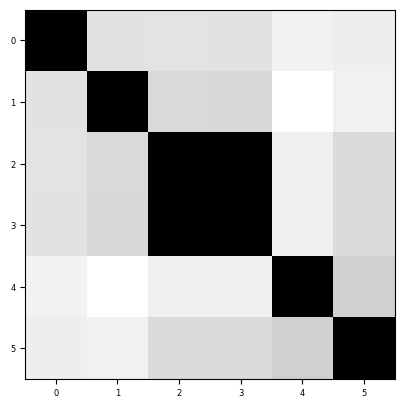

In [38]:
fig, ax = plt.subplots()
im = ax.imshow(np.corrcoef(

    [
        dwca_infos["raw_size_bytes"], # 0
        paper_infos["file_size_bytes"], # 1
        dwc_file_overviews["nr_elements"], # 2
        dwc_file_overviews["total_attributes"], # 3 
        eml_file_overviews["nr_elements"], # 4
        eml_file_overviews["total_attributes"], # 5 
    ]
), cmap="Grays")

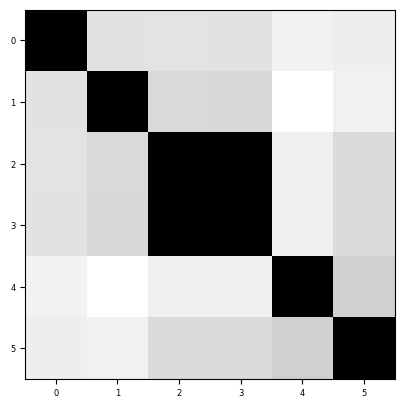

In [39]:
fig, ax = plt.subplots()
im = ax.imshow(np.corrcoef(
    [
        dwca_infos["raw_size_bytes"],
        paper_infos["file_size_bytes"],
        dwc_file_overviews["nr_elements"], 
        dwc_file_overviews["total_attributes"], 
        eml_file_overviews["nr_elements"], 
        eml_file_overviews["total_attributes"], 
    ]
), cmap="Grays")

In [40]:
def get_average_group(df, attribute):
    low = df[attribute].quantile(0.25)
    high = df[attribute].quantile(0.75)
    print(attribute, low, high)
    return df[(df[attribute] >= low) & (df[attribute] <= high)]

In [41]:
dwca_avg_uncompressed_size = get_average_group(dwca_infos, "raw_size_bytes")
paper_avg_size = get_average_group(paper_infos, "file_size_bytes")

dwc_avg_nr_elements = get_average_group(dwc_file_overviews, "nr_elements")
dwc_avg_nr_attributes = get_average_group(dwc_file_overviews, "total_attributes")

eml_avg_nr_elements = get_average_group(eml_file_overviews, "nr_elements")
eml_avg_nr_attributes = get_average_group(eml_file_overviews, "total_attributes")

raw_size_bytes 359299.5 8630822.0
file_size_bytes 378799.5 1490002.0
nr_elements 33.5 61.0
total_attributes 65.0 119.0
nr_elements 142.0 331.5
total_attributes 11.0 22.0


In [42]:
avg_groups = [
    # dwca_avg_uncompressed_size,
    # paper_avg_size,
    dwc_avg_nr_elements,
    # dwc_avg_nr_attributes,
    eml_avg_nr_elements,
    # eml_avg_nr_attributes
]

In [43]:
avg_index = pd.Index(list(set.intersection(*map(lambda x: set(x.index), avg_groups))))

In [44]:
gbif_cases.loc[avg_index].describe()

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,data_standard,year,best_oa_location.repository_institution,first_oa_location.repository_institution,best_oa_location,first_oa_location
count,48.000000,48.000000,48.000000,48.000000,48.000000,48.0,48.000000,0.0,0.0,0.0,0.0
mean,90.416667,106.875000,144.083333,155.520833,155.520833,2.0,2024.020833,NaN,NaN,NaN,NaN
std,51.140954,62.458028,92.446151,99.369714,99.369714,0.0,1.344644,NaN,NaN,NaN,NaN
min,14.000000,15.000000,16.000000,16.000000,16.000000,2.0,2022.000000,NaN,NaN,NaN,NaN
25%,47.500000,56.500000,66.000000,72.000000,72.000000,2.0,2023.000000,NaN,NaN,NaN,NaN
50%,82.000000,93.000000,129.000000,141.000000,141.000000,2.0,2024.000000,NaN,NaN,NaN,NaN
75%,137.750000,166.250000,223.500000,239.500000,239.500000,2.0,2025.000000,NaN,NaN,NaN,NaN
max,174.000000,208.000000,301.000000,323.000000,323.000000,2.0,2026.000000,NaN,NaN,NaN,NaN


In [45]:
dwc_file_overviews.loc[avg_index]

,file_path,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
131,../../_data/gbif_data_archive/ground_truth/dat...,52,6,102,1.961538,3,0.980769,14,1,1.961538
132,../../_data/gbif_data_archive/ground_truth/dat...,47,8,91,1.957447,3,0.978723,23,2,1.936170
137,../../_data/gbif_data_archive/ground_truth/dat...,54,8,105,1.962963,3,0.981481,23,2,1.944444
140,../../_data/gbif_data_archive/ground_truth/dat...,44,6,86,1.954545,3,0.977273,14,1,1.954545
141,../../_data/gbif_data_archive/ground_truth/dat...,34,6,66,1.941176,3,0.970588,14,1,1.941176
14,../../_data/gbif_data_archive/ground_truth/dat...,51,8,99,1.960784,3,0.980392,38,2,1.941176
17,../../_data/gbif_data_archive/ground_truth/dat...,54,6,106,1.962963,3,0.981481,14,1,1.962963
18,../../_data/gbif_data_archive/ground_truth/dat...,43,8,83,1.953488,3,0.976744,23,2,1.930233
145,../../_data/gbif_data_archive/ground_truth/dat...,38,6,77,1.947368,3,0.973684,14,1,2.026316
149,../../_data/gbif_data_archive/ground_truth/dat...,41,6,80,1.951220,3,0.975610,14,1,1.951220


In [46]:
features = pd.DataFrame({
    "dwca_size": dwca_infos["raw_size_bytes"],
    "paper_size": paper_infos["file_size_bytes"],
    "dwc_elements": dwc_file_overviews["nr_elements"],
    "eml_elements": eml_file_overviews["nr_elements"]
})

def robust_score(series):
    return ((series - series.median()) / (series.quantile(0.75) - series.quantile(0.25))) ** 2

normalized_scores = features.apply(robust_score)
features['average_dist'] = normalized_scores.sum(axis=1)

n_sample = int(len(features) * 0.20)
avg_dist_index = features['average_dist'].nsmallest(n_sample).index
gbif_avg_sample = gbif_cases.loc[avg_dist_index]

gbif_avg_sample.describe()

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,data_standard,year,best_oa_location.repository_institution,first_oa_location.repository_institution,best_oa_location,first_oa_location
count,35.000000,35.000000,35.000000,35.000000,35.000000,35.0,35.000000,0.0,0.0,0.0,0.0
mean,86.457143,102.200000,137.371429,148.114286,148.114286,2.0,2024.142857,NaN,NaN,NaN,NaN
std,50.940763,62.301355,91.006815,98.170551,98.170551,0.0,1.331581,NaN,NaN,NaN,NaN
min,12.000000,13.000000,14.000000,14.000000,14.000000,2.0,2022.000000,NaN,NaN,NaN,NaN
25%,41.000000,50.000000,58.000000,64.000000,64.000000,2.0,2023.000000,NaN,NaN,NaN,NaN
50%,86.000000,97.000000,136.000000,148.000000,148.000000,2.0,2024.000000,NaN,NaN,NaN,NaN
75%,131.000000,158.500000,213.000000,229.000000,229.000000,2.0,2025.000000,NaN,NaN,NaN,NaN
max,171.000000,205.000000,294.000000,316.000000,316.000000,2.0,2026.000000,NaN,NaN,NaN,NaN


In [47]:
len(avg_index.intersection(avg_dist_index))

26

In [48]:
from sklearn.preprocessing import RobustScaler

In [49]:
scaler = RobustScaler()
scaled_data = scaler.fit_transform(features)

In [50]:
squared_distances = np.sum(np.square(scaled_data), axis=1)
dist_series = pd.Series(squared_distances, index=features.index)

In [51]:
n_sample = int(len(dist_series) * 0.10)
avg_scaler_index = dist_series.nsmallest(n_sample).index

In [52]:
len(avg_index.intersection(avg_scaler_index))

16

In [53]:
gbif_avg_sample = gbif_cases.loc[avg_scaler_index]

gbif_avg_sample.describe()

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,data_standard,year,best_oa_location.repository_institution,first_oa_location.repository_institution,best_oa_location,first_oa_location
count,17.000000,17.000000,17.000000,17.000000,17.000000,17.0,17.000000,0.0,0.0,0.0,0.0
mean,93.941176,111.705882,152.529412,164.352941,164.352941,2.0,2023.941176,NaN,NaN,NaN,NaN
std,59.622218,72.612641,107.804289,116.372216,116.372216,0.0,1.560072,NaN,NaN,NaN,NaN
min,18.000000,19.000000,20.000000,20.000000,20.000000,2.0,2022.000000,NaN,NaN,NaN,NaN
25%,39.000000,48.000000,56.000000,62.000000,62.000000,2.0,2023.000000,NaN,NaN,NaN,NaN
50%,86.000000,97.000000,136.000000,148.000000,148.000000,2.0,2024.000000,NaN,NaN,NaN,NaN
75%,149.000000,180.000000,249.000000,269.000000,269.000000,2.0,2025.000000,NaN,NaN,NaN,NaN
max,171.000000,205.000000,294.000000,316.000000,316.000000,2.0,2026.000000,NaN,NaN,NaN,NaN


In [54]:
dropped_rows = avg_index.difference(avg_dist_index)

In [55]:
normalized_scores.loc[dropped_rows]

,dwca_size,paper_size,dwc_elements,eml_elements
17,0.032235,2.974929,0.107107,0.006266
34,0.061695,14.278105,0.021157,0.196490
38,7029.653799,0.096875,0.000000,0.004010
49,0.030300,0.250095,0.001322,0.256640
54,5.290772,0.000000,0.005289,0.103619
61,0.476193,0.003034,0.033058,0.100250
64,0.025025,3.730565,0.064793,0.235699
65,0.020216,1.219266,0.259174,0.301195
66,0.207660,0.021109,0.259174,0.187245
69,0.041012,0.402224,0.084628,0.000000


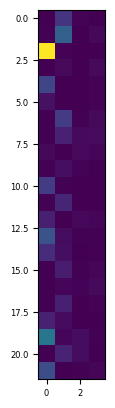

In [56]:
fig, ax = plt.subplots(1,1)
ax.imshow(np.log1p(np.array(normalized_scores.loc[dropped_rows])))

In [57]:
dwc_file_overviews.loc[34]

file_path             ../../_data/gbif_data_archive/ground_truth/dat...
nr_elements                                                          49
nr_unique_elements                                                    8
total_attributes                                                     95
avg_depth                                                      1.959184
max_depth                                                             3
avg_fanout                                                     0.979592
total_text_length                                                    28
nr_text_nodes                                                         2
attr_density                                                   1.938776
Name: 34, dtype: object

In [58]:
dwc_file_overviews.describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,179.000000,179.000000,179.000000,179.000000,179.0,179.000000,179.000000,179.000000,179.000000
mean,49.307263,6.905028,96.340782,1.951754,3.0,0.975877,21.921788,1.569832,1.948139
std,23.171091,1.003884,46.010393,0.021203,0.0,0.010602,12.404445,0.718445,0.033823
min,12.000000,6.000000,22.000000,1.833333,3.0,0.916667,8.000000,1.000000,1.833333
25%,33.500000,6.000000,65.000000,1.940285,3.0,0.970143,14.000000,1.000000,1.931426
50%,45.000000,6.000000,90.000000,1.955556,3.0,0.977778,14.000000,1.000000,1.948718
75%,61.000000,8.000000,119.000000,1.967213,3.0,0.983607,23.000000,2.000000,1.956202
max,202.000000,9.000000,401.000000,1.990099,3.0,0.995050,74.000000,4.000000,2.090909


In [59]:
dwc_file_overviews.loc[avg_index].describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,48.000000,48.000000,48.000000,48.000000,48.0,48.000000,48.000000,48.000000,48.000000
mean,46.770833,6.916667,91.208333,1.956335,3.0,0.978167,20.770833,1.520833,1.950097
std,6.861051,1.007067,13.462254,0.006379,0.0,0.003189,9.711234,0.618495,0.021584
min,34.000000,6.000000,66.000000,1.941176,3.0,0.970588,14.000000,1.000000,1.906977
25%,41.750000,6.000000,81.500000,1.952091,3.0,0.976045,14.000000,1.000000,1.938776
50%,46.500000,6.000000,90.500000,1.956984,3.0,0.978492,14.000000,1.000000,1.949576
75%,51.250000,8.000000,99.500000,1.960973,3.0,0.980486,23.000000,2.000000,1.956753
max,61.000000,8.000000,120.000000,1.967213,3.0,0.983607,52.000000,3.000000,2.026316


In [60]:
dwc_file_overviews.loc[avg_dist_index].describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,35.000000,35.000000,35.000000,35.000000,35.0,35.000000,35.000000,35.000000,35.000000
mean,43.142857,6.742857,84.114286,1.952340,3.0,0.976170,19.085714,1.400000,1.949290
std,7.000600,0.980482,13.789961,0.008415,0.0,0.004207,8.290219,0.553066,0.023829
min,30.000000,6.000000,58.000000,1.933333,3.0,0.966667,14.000000,1.000000,1.923077
25%,39.000000,6.000000,76.500000,1.948718,3.0,0.974359,14.000000,1.000000,1.933333
50%,43.000000,6.000000,83.000000,1.953488,3.0,0.976744,14.000000,1.000000,1.941176
75%,48.500000,8.000000,94.500000,1.958759,3.0,0.979379,23.000000,2.000000,1.955996
max,58.000000,8.000000,114.000000,1.965517,3.0,0.982759,44.000000,3.000000,2.026316


In [61]:
dwc_file_overviews.loc[avg_scaler_index].describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,17.000000,17.000000,17.000000,17.000000,17.0,17.000000,17.000000,17.000000,17.000000
mean,42.294118,6.941176,82.411765,1.952365,3.0,0.976182,19.411765,1.470588,1.949915
std,3.704131,1.028992,6.605479,0.004241,0.0,0.002121,7.542039,0.514496,0.025822
min,35.000000,6.000000,70.000000,1.942857,3.0,0.971429,14.000000,1.000000,1.930233
25%,40.000000,6.000000,78.000000,1.950000,3.0,0.975000,14.000000,1.000000,1.931818
50%,43.000000,6.000000,83.000000,1.953488,3.0,0.976744,14.000000,1.000000,1.947368
75%,44.000000,8.000000,85.000000,1.954545,3.0,0.977273,23.000000,2.000000,1.951220
max,49.000000,8.000000,95.000000,1.959184,3.0,0.979592,43.000000,2.000000,2.026316


In [62]:
eml_file_overviews.describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000
mean,299.810056,69.016760,18.245810,3.582100,5.932961,0.994477,10202.379888,200.480447,0.077726
std,494.601131,12.220114,13.199248,0.308271,0.431847,0.003963,8481.407882,331.266761,0.034424
min,31.000000,25.000000,5.000000,2.794872,4.000000,0.967742,531.000000,17.000000,0.003320
25%,142.000000,63.000000,11.000000,3.397895,6.000000,0.992958,3856.000000,92.000000,0.054033
50%,206.000000,70.000000,15.000000,3.506711,6.000000,0.995146,8575.000000,135.000000,0.075581
75%,331.500000,76.500000,22.000000,3.746636,6.000000,0.996983,13711.500000,229.000000,0.095698
max,6326.000000,98.000000,126.000000,4.634366,8.000000,0.999842,59136.000000,4210.000000,0.265873


In [63]:
eml_file_overviews.loc[avg_index].describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,48.000000,48.000000,48.000000,48.000000,48.000000,48.000000,48.000000,48.000000,48.000000
mean,217.500000,71.000000,17.729167,3.637516,5.979167,0.995141,10780.458333,144.312500,0.080675
std,52.021681,7.830654,10.448943,0.206997,0.251767,0.001137,7873.087866,41.832572,0.037591
min,142.000000,55.000000,7.000000,3.218310,5.000000,0.992958,1862.000000,87.000000,0.028807
25%,173.750000,66.000000,11.000000,3.494020,6.000000,0.994245,5811.750000,111.500000,0.061502
50%,203.000000,69.500000,15.000000,3.587963,6.000000,0.995074,8313.500000,133.000000,0.076011
75%,266.250000,76.250000,22.250000,3.738608,6.000000,0.996244,13297.250000,179.750000,0.096253
max,310.000000,89.000000,67.000000,4.232639,7.000000,0.996774,36736.000000,249.000000,0.265873


In [64]:
eml_file_overviews.loc[avg_dist_index].describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000,35.000000
mean,193.685714,70.571429,15.771429,3.580517,5.971429,0.994522,8570.371429,126.028571,0.080596
std,47.435263,8.171996,10.524721,0.180334,0.169031,0.001377,6850.411212,34.488264,0.039459
min,107.000000,44.000000,7.000000,3.151316,5.000000,0.990654,2510.000000,67.000000,0.028807
25%,159.000000,66.000000,10.000000,3.467257,6.000000,0.993707,4564.500000,101.500000,0.063428
50%,185.000000,72.000000,13.000000,3.554113,6.000000,0.994595,6683.000000,115.000000,0.083333
75%,230.500000,76.000000,17.000000,3.661680,6.000000,0.995662,9173.000000,144.000000,0.089691
max,292.000000,88.000000,67.000000,4.120000,6.000000,0.996575,36736.000000,208.000000,0.265873


In [65]:
eml_file_overviews.loc[avg_scaler_index].describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,17.000000,17.000000,17.000000,17.000000,17.0,17.000000,17.000000,17.000000,17.000000
mean,198.294118,70.470588,16.647059,3.654618,6.0,0.994786,8202.000000,128.823529,0.081503
std,37.211834,7.459203,14.075427,0.186154,0.0,0.000981,7699.359681,28.143017,0.053347
min,139.000000,60.000000,7.000000,3.417266,6.0,0.992806,3286.000000,90.000000,0.028807
25%,173.000000,66.000000,10.000000,3.514851,6.0,0.994220,5053.000000,109.000000,0.062500
50%,189.000000,71.000000,13.000000,3.617284,6.0,0.994709,6332.000000,123.000000,0.075581
75%,231.000000,74.000000,16.000000,3.732558,6.0,0.995671,7142.000000,138.000000,0.089494
max,257.000000,88.000000,67.000000,4.120000,6.0,0.996109,36736.000000,182.000000,0.265873


{'whiskers': [<matplotlib.lines.Line2D at 0x119ce39d0>,
 'caps': [<matplotlib.lines.Line2D at 0x119ce3c50>,
 'boxes': [<matplotlib.lines.Line2D at 0x119ce3890>,
 'medians': [<matplotlib.lines.Line2D at 0x119ce3ed0>,
 'fliers': [<matplotlib.lines.Line2D at 0x119d44050>,
 'means': []}

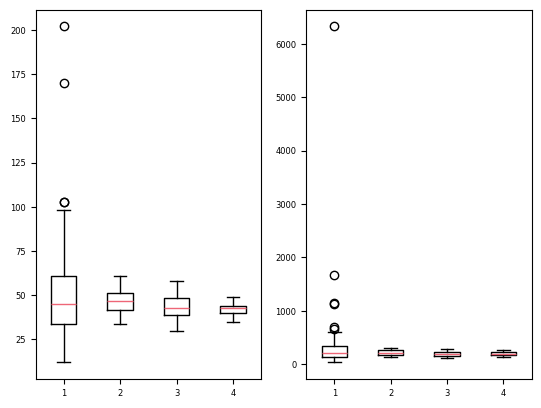

In [66]:
fig, (ax1, ax2) = plt.subplots(1,2)

ax1.boxplot([
    dwc_file_overviews["nr_elements"],
    dwc_file_overviews.loc[avg_index]["nr_elements"],
    dwc_file_overviews.loc[avg_dist_index]["nr_elements"],
    dwc_file_overviews.loc[avg_scaler_index]["nr_elements"],
])

ax2.boxplot([
    eml_file_overviews["nr_elements"],
    eml_file_overviews.loc[avg_index]["nr_elements"],
    eml_file_overviews.loc[avg_dist_index]["nr_elements"],
    eml_file_overviews.loc[avg_scaler_index]["nr_elements"],
])

In [67]:
gbif_avg_sample = gbif_cases.loc[avg_scaler_index]

In [68]:
gbif_avg_sample.index

Index([43, 24, 39, 169, 145, 166, 132, 171, 118, 23, 18, 149, 86, 27, 84, 45,
       158],
      dtype='int64')

In [69]:
gbif_avg_sample.to_csv("subsample_average_gbif_cases.csv")